### 딥러닝 실습

In [ ]:
import torch

# PyTorch를 통한 GPU 사용 가능 여부 확인
gpu_available = torch.cuda.is_available()
print(f"GPU Aㅁvailable: {gpu_available}")

if gpu_available:
    print(f"GPU Count: {torch.cuda.device_count()}")
    print(f"Current GPU Index: {torch.cuda.current_device()}")
    print(f"GPU Name: {torch.cuda.get_device_name(0)}")
else:
    print("No GPU detected by PyTorch.")

print("\n--- System GPU Status (nvidia-smi) ---")
# 시스템 전체 GPU 상태 확인
!nvidia-smi

GPU Available: True
GPU Count: 1
Current GPU Index: 0
GPU Name: Tesla T4

--- System GPU Status (nvidia-smi) ---
Thu Oct 22 07:47:32 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             13W /   70W |       3MiB /  15360MiB |      0%      Default |
|                          

In [ ]:
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.preprocessing import StandardScaler

# 1. 데이터 로드
train_df = pd.read_csv('/content/boston_train.csv')
test_df = pd.read_csv('/content/boston_test.csv')

# CSV 파일 내의 실제 대문자 컬럼명 'MEDV'로 수정합니다.
target_col = 'MEDV'

X_train = train_df.drop(columns=[target_col])
y_train = train_df[target_col]
X_test = test_df.drop(columns=[target_col])
y_test = test_df[target_col]

# 2. 데이터 표준화 (Feature Scaling)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train shape: {X_train_scaled.shape}, Test shape: {X_test_scaled.shape}")

Train shape: (400, 9), Test shape: (100, 9)


In [ ]:
# 3. 텐서플로 회귀 모델 구축
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(64, activation='relu'),
    layers.Dense(32, activation='relu'),
    layers.Dense(1)  # 회귀 문제이므로 활성화 함수 없이 출력 뉴런 1개
])

# 모델 컴파일 (손실함수: MSE, 평가 지표: MAE)
model.compile(optimizer='adam', loss='mse', metrics=['mae'])

# 4. 모델 학습
history = model.fit(
    X_train_scaled, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 576.9290 - mae: 22.0069 - val_loss: 575.3199 - val_mae: 22.1661
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 521.8647 - mae: 20.7916 - val_loss: 498.5230 - val_mae: 20.4919
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 443.8382 - mae: 18.9262 - val_loss: 386.1450 - val_mae: 17.7609
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 337.5070 - mae: 15.9581 - val_loss: 246.0323 - val_mae: 13.6129
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 215.5644 - mae: 12.0062 - val_loss: 132.4462 - val_mae: 9.0809
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 129.4521 - mae: 8.5480 - val_loss: 76.8621 - val_mae: 6.7092
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 84.4016 - mae: 6.8260 - val_loss: 58.1973 - val_mae: 5.9999
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 64.3890 - mae: 5.9843 - val_loss: 45.0408 - val_mae: 5.2291
Epoch 9/100
20/20 ━━━━━━━━━

In [ ]:
import numpy as np
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 5. 테스트 데이터를 활용한 모델 예측 및 평가
loss, mae = model.evaluate(X_test_scaled, y_test, verbose=0)
predictions = model.predict(X_test_scaled).flatten()

mse = mean_squared_error(y_test, predictions)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, predictions)

print("=== Boston Test Dataset Evaluation ===")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"Mean Squared Error (MSE): {mse:.4f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.4f}")
print(f"R-squared (R2 Score): {r2:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step
=== Boston Test Dataset Evaluation ===
Mean Absolute Error (MAE): 2.5561
Mean Squared Error (MSE): 10.6204
Root Mean Squared Error (RMSE): 3.2589
R-squared (R2 Score): 0.8109


In [ ]:
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, accuracy_score

# 1. 데이터 로드
iris_df = pd.read_csv('/content/iris.csv')

# 데이터프레임 구조에 따라 독립변수(X)와 종속변수(y) 추출
target_col = iris_df.columns[-1]
X = iris_df.drop(columns=[target_col])
y = iris_df[target_col]

# 2. 레이블 인코딩 및 원-핫 인코딩
le = LabelEncoder()
y_encoded = le.fit_transform(y)
y_categorical = tf.keras.utils.to_categorical(y_encoded)

# 3. 데이터 분할
X_train, X_test, y_train, y_test = train_test_split(
    X, y_categorical, test_size=0.2, random_state=42, stratify=y_encoded
)

# 4. 특성 스케일링
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 5. 모델 빌드 및 학습
model = models.Sequential([
    layers.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(32, activation='relu'),
    layers.Dense(16, activation='relu'),
    layers.Dense(y_categorical.shape[1], activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

history = model.fit(
    X_train_scaled, y_train,
    epochs=80,
    batch_size=8,
    validation_split=0.1,
    verbose=0
)

# 6. 모델 평가
loss, accuracy = model.evaluate(X_test_scaled, y_test, verbose=0)
y_pred = model.predict(X_test_scaled)
y_pred_classes = np.argmax(y_pred, axis=1)
y_test_classes = np.argmax(y_test, axis=1)

# target_names의 모든 요소를 문자열로 강제 형변환하여 에러 방지
target_names = [str(cls) for cls in le.classes_]

print("=== Iris Dataset Evaluation ===")
print(f"Test Loss: {loss:.4f}")
print(f"Test Accuracy: {accuracy:.4f}\n")
print("--- Classification Report ---")
print(classification_report(y_test_classes, y_pred_classes, target_names=target_names))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 182ms/step
=== Iris Dataset Evaluation ===
Test Loss: 0.1198
Test Accuracy: 0.9333

--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        10
           1       0.90      0.90      0.90        10
           2       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [ ]:
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
import numpy as np

# 1. MNIST 손글씨 데이터셋 다운로드 및 로드
# 28x28 크기의 흑백 손글씨 숫자(0~9) 이미지 데이터셋입니다.
(train_images, train_labels), (test_images, test_labels) = datasets.mnist.load_data()

# 2. 데이터 전처리 (Preprocessing)
# 픽셀 값을 0~1 사이로 정규화합니다.
train_images = train_images / 255.0
test_images = test_images / 255.0

# CNN 모델의 입력을 위해 흑백 채널 차원(1)을 명시적으로 추가합니다. (28, 28) -> (28, 28, 1)
train_images = np.expand_dims(train_images, axis=-1)
test_images = np.expand_dims(test_images, axis=-1)

print(f"Train images shape: {train_images.shape}")
print(f"Test images shape: {test_images.shape}")

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Train images shape: (60000, 28, 28, 1)
Test images shape: (10000, 28, 28, 1)


In [ ]:
# 3. 합성곱 신경망(CNN) 모델 구성
model = models.Sequential([
    # 특징 추출을 위한 Conv 레이어 및 Max Pooling
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    # Dense 레이어로 전달하기 위해 Flat하게 펼치기
    layers.Flatten(),
    layers.Dense(64, activation='relu'),

    # 0부터 9까지 총 10개의 클래스 출력을 위해 Softmax 적용
    layers.Dense(10, activation='softmax')
])

# 모델 아키텍처 요약 정보 출력
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# 4. 모델 컴파일 및 학습 진행
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# GPU 가속을 활용해 빠른 속도로 5 epoch 동안 학습합니다.
history = model.fit(train_images, train_labels, epochs=5,
                    validation_data=(test_images, test_labels),
                    batch_size=64)

# 5. 테스트셋 최종 평가지표 산출
test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=0)
print(f"\n=== MNIST 테스트 데이터셋 평가 ===")
print(f"테스트 손실(Test Loss): {test_loss:.4f}")
print(f"테스트 정확도(Test Accuracy): {test_acc:.4f}")

Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 14s 10ms/step - accuracy: 0.9435 - loss: 0.1862 - val_accuracy: 0.9820 - val_loss: 0.0563
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9827 - loss: 0.0570 - val_accuracy: 0.9881 - val_loss: 0.0350
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9886 - loss: 0.0382 - val_accuracy: 0.9871 - val_loss: 0.0378
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9908 - loss: 0.0298 - val_accuracy: 0.9895 - val_loss: 0.0278
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9928 - loss: 0.0226 - val_accuracy: 0.9902 - val_loss: 0.0299

=== MNIST 테스트 데이터셋 평가 ===
테스트 손실(Test Loss): 0.0299
테스트 정확도(Test Accuracy): 0.9902


### 🔍 MNIST 손글씨 딥러닝 이미지 분류 소스 코드 상세 분석

#### 1. 데이터 로드 및 차원 전처리
* **`datasets.mnist.load_data()`**: 텐서플로 내부에서 제공하는 6만 개의 학습 데이터와 1만 개의 테스트용 0~9 손글씨 이미지 쌍을 불러옵니다.
* **채널 차원 추가 (`np.expand_dims`)**: 원본 흑백 이미지는 2차원 `(28, 28)` 형태를 갖습니다. 텐서플로의 `Conv2D` 레이어는 채널 차원을 포함한 3차원 텐서 `(가로, 세로, 채널)` 형태를 필수로 요구하므로, `(28, 28, 1)`로 형태를 확장해 줍니다.

#### 2. 모델 레이어 상세 설계
* **`Conv2D` (Convolutional Layer)**: 이미지 필터 연산을 통해 픽셀 간의 지역적 공간 특징(선, 면, 굴곡 등)을 추출합니다.
* **`MaxPooling2D`**: 특정 크기의 영역(2x2)에서 가장 지배적인 특징값을 뽑아내어 이미지 해상도를 절반으로 줄이며 계산 비용을 낮추고 노이즈를 억제합니다.
* **`Flatten` 및 `Dense`**: CNN 영역에서 추출해 낸 공간 특징 정보를 1차원 벡터로 일렬 정렬한 뒤, 완전연결 신경망(Fully-Connected Layer)을 통해 최종 숫자가 무엇인지 추론하고 다중 분류 출력을 산출합니다.

#### 3. 컴파일 및 학습 파라미터
* **`sparse_categorical_crossentropy`**: 0~9의 단일 정수 레이블을 인코딩 없이 손실함수로 사용하여 학습할 수 있도록 지원하는 특수한 다중 클래스 엔트로피 손실 함수입니다.
* **`Adam Optimizer`**: 모멘텀(Momentum)과 RMSProp 방식의 이점을 결합하여 보편적으로 수렴 성능이 가장 뛰어난 경사 하강 학습 최적화 도구입니다.

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


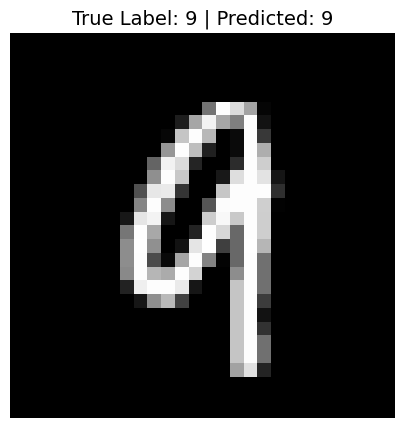

=== 클래스별 예측 확률 (0~9) ===
숫자 0: 0.00%
숫자 1: 0.00%
숫자 2: 0.00%
숫자 3: 0.00%
숫자 4: 0.02%
숫자 5: 0.00%
숫자 6: 0.00%
숫자 7: 0.00%
숫자 8: 0.00%
숫자 9: 99.98%


In [ ]:
import matplotlib.pyplot as plt
import random

# 1. 테스트 데이터셋에서 무작위로 하나의 이미지 선택
random_idx = random.randint(0, len(test_images) - 1)
test_image = test_images[random_idx]
test_label = test_labels[random_idx]

# 2. 모델 예측을 위해 배치 차원 추가 (1, 28, 28, 1)
input_image = np.expand_dims(test_image, axis=0)
prediction = model.predict(input_image)
predicted_label = np.argmax(prediction)

# 3. 이미지 출력 및 예측 결과 표시
plt.figure(figsize=(5, 5))
plt.imshow(test_image.squeeze(), cmap='gray')
plt.title(f"True Label: {test_label} | Predicted: {predicted_label}", fontsize=14)
plt.axis('off')
plt.show()

# 예측 클래스별 확률 분포 확인
print("=== 클래스별 예측 확률 (0~9) ===")
for i, prob in enumerate(prediction[0]):
    print(f"숫자 {i}: {prob*100:.2f}%")

예측할 손글씨 이미지 파일을 업로드해주세요 (png, jpg 등):


Saving 스크린샷 2026-10-22 173448.png to 스크린샷 2026-10-22 173448.png
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 53356 (\N{HANGUL SYLLABLE KEU}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 47536 (\N{HANGUL SYLLABLE RIN}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 49399 (\N{HANGUL SYLLABLE SYAS}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


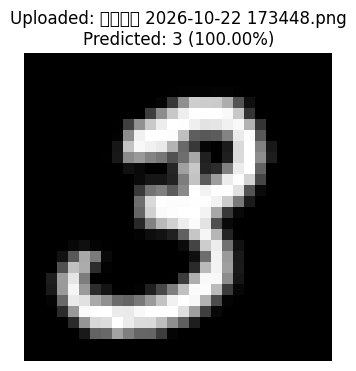

In [ ]:
from google.colab import files
from PIL import Image
import io
import numpy as np
import matplotlib.pyplot as plt

# 1. 파일 업로드 받기
print("예측할 손글씨 이미지 파일을 업로드해주세요 (png, jpg 등):")
uploaded = files.upload()

for fn in uploaded.keys():
    # 2. 이미지 불러오기 및 흑백 변환
    image_data = uploaded[fn]
    img = Image.open(io.BytesIO(image_data)).convert('L')

    # 3. 크기를 28x28 픽셀로 자동 리사이징
    img_resized = img.resize((28, 28))

    # 4. numpy 배열로 변환 및 전처리
    # MNIST 모델은 배경이 검은색(0)이고 글씨가 흰색(255)인 형태를 학습했습니다.
    # 만약 업로드한 이미지가 흰 바탕에 검은 글씨라면 반전(Invert) 처리가 필요할 수 있습니다.
    img_array = np.array(img_resized)

    # 간단히 배경색 판별 후 필요시 색상 반전 (배경이 밝으면 반전)
    if np.mean(img_array[:4, :4]) > 127:
        img_array = 255 - img_array

    # 0~1 사이 정규화
    img_normalized = img_array / 255.0

    # 모델 입력을 위한 차원 조정 (1, 28, 28, 1)
    img_input = np.expand_dims(img_normalized, axis=(0, -1))

    # 5. 모델 예측
    pred = model.predict(img_input)
    pred_label = np.argmax(pred)
    confidence = pred[0][pred_label] * 100

    # 6. 결과 시각화
    plt.figure(figsize=(4, 4))
    plt.imshow(img_normalized, cmap='gray')
    plt.title(f"Uploaded: {fn}\nPredicted: {pred_label} ({confidence:.2f}%)", fontsize=12)
    plt.axis('off')
    plt.show()

In [1]:
import numpy as np
import tensorflow as tf
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.sequence import pad_sequences

# 1. IMDB 데이터셋 로드 (가장 자주 등장하는 10,000개 단어 대상)
max_features = 10000
(X_train, y_train), (X_test, y_test) = datasets.imdb.load_data(num_words=max_features)

# 2. 데이터 패딩 (시퀀스 길이를 200으로 통일)
maxlen = 200
X_train_padded = pad_sequences(X_train, maxlen=maxlen, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test, maxlen=maxlen, padding='post', truncating='post')

print(f"Train data shape: {X_train_padded.shape}")
print(f"Test data shape: {X_test_padded.shape}")

# 3. 자연어 분류 딥러닝 모델 설계
model = models.Sequential([
    # Embedding Layer: 단어 정수를 128차원의 밀집 벡터로 변환
    layers.Embedding(input_dim=max_features, output_dim=128, input_length=maxlen),

    # Global Average Pooling: 문장 전체의 임베딩 평균값을 취해 평탄화
    layers.GlobalAveragePooling1D(),

    # Fully Connected Layer
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),

    # Output Layer (이진 분류: 긍정/부정)
    layers.Dense(1, activation='sigmoid')
])

# 4. 모델 컴파일 및 학습 설정
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 5. 모델 학습 시작
history = model.fit(
    X_train_padded, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

# 6. 테스트 데이터셋 평가
test_loss, test_acc = model.evaluate(X_test_padded, y_test, verbose=0)
print("\n=== IMDB 감성 분석 모델 평가 ===")
print(f"테스트 손실 (Test Loss)    : {test_loss:.4f}")
print(f"테스트 정확도 (Test Accuracy): {test_acc:.4f}")


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Train data shape: (25000, 200)
Test data shape: (25000, 200)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ ?                      │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - accuracy: 0.7284 - loss: 0.5368 - val_accuracy: 0.8542 - val_loss: 0.3633
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8723 - loss: 0.3101 - val_accuracy: 0.8696 - val_loss: 0.3201
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9035 - loss: 0.2491 - val_accuracy: 0.8648 - val_loss: 0.3312
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9204 - loss: 0.2100 - val_accuracy: 0.8688 - val_loss: 0.3310
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9280 - loss: 0.1915 - val_accuracy: 0.8734 - val_loss: 0.3361
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9421 - loss: 0.1628 - val_accuracy: 0.8724 - val_loss: 0.3504
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9517 - loss: 0.1449 - val_accuracy: 0.8490 - val_loss: 0.4082
Epoch 8/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9567 - loss: 0.1301 - val_accuracy: 0

In [4]:
import urllib.request
import pandas as pd
import numpy as np
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras import layers, models

# 1. 네이버 영화 리뷰 데이터셋(NSMC) 다운로드 및 로드
print("데이터를 다운로드하고 있습니다...")
urllib.request.urlretrieve("https://raw.githubusercontent.com/e9t/nsmc/master/ratings_train.txt", filename="ratings_train.txt")
urllib.request.urlretrieve("https://raw.githubusercontent.com/e9t/nsmc/master/ratings_test.txt", filename="ratings_test.txt")

train_data = pd.read_table('ratings_train.txt')
test_data = pd.read_table('ratings_test.txt')

# 2. 데이터 정제 (결측치 제거 및 중복 제거)
train_data.drop_duplicates(subset=['document'], inplace=True)
train_data = train_data.dropna(how='any')
test_data = test_data.dropna(how='any')

# 학습 속도를 위해 상위 20,000개 데이터 샘플만 빌드에 활용합니다.
train_data = train_data.sample(n=20000, random_state=42)
test_data = test_data.sample(n=5000, random_state=42)

X_train_sentences = train_data['document'].values
y_train = train_data['label'].values
X_test_sentences = test_data['document'].values
y_test = test_data['label'].values

# 3. 토큰화 (Tokenizer) 및 정수 인코딩
# 한국어 원형 복원을 위한 형태소 분석기 없이 공백 및 글자 단위 형태의 기본적인 토크나이저를 사용합니다.
max_words = 15000
tokenizer = Tokenizer(num_words=max_words, oov_token='<OOV>')
tokenizer.fit_on_texts(X_train_sentences)

X_train_sequences = tokenizer.texts_to_sequences(X_train_sentences)
X_test_sequences = tokenizer.texts_to_sequences(X_test_sentences)

# 4. 패딩 작업
maxlen = 40
X_train_padded = pad_sequences(X_train_sequences, maxlen=maxlen, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test_sequences, maxlen=maxlen, padding='post', truncating='post')

# 5. LSTM 기반 자연어 처리 분류 모델 설계
model = models.Sequential([
    # 고밀도 임베딩 벡터 변환
    layers.Embedding(input_dim=max_words, output_dim=100, input_length=maxlen),
    # 양방향 LSTM을 적용하여 문장의 순방향/역방향 문맥을 모두 학습
    layers.Bidirectional(layers.LSTM(64, return_sequences=False)),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

# 6. 모델 학습 진행
print("모델 학습을 시작합니다...")
history = model.fit(
    X_train_padded, y_train,
    epochs=5,
    batch_size=128,
    validation_split=0.1,
    verbose=1
)

# 7. 평가
test_loss, test_acc = model.evaluate(X_test_padded, y_test, verbose=0)
print("\n=== 네이버 영화 리뷰 감성 분류 평가 ===")
print(f"테스트 정확도: {test_acc*100:.2f}%")


데이터를 다운로드하고 있습니다...


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

모델 학습을 시작합니다...
Epoch 1/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.6308 - loss: 0.6138 - val_accuracy: 0.7730 - val_loss: 0.4587
Epoch 2/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8323 - loss: 0.3697 - val_accuracy: 0.7830 - val_loss: 0.4573
Epoch 3/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.8911 - loss: 0.2461 - val_accuracy: 0.7870 - val_loss: 0.4892
Epoch 4/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9108 - loss: 0.1940 - val_accuracy: 0.7810 - val_loss: 0.5657
Epoch 5/5
141/141 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.9265 - loss: 0.1593 - val_accuracy: 0.7725 - val_loss: 0.6866

=== 네이버 영화 리뷰 감성 분류 평가 ===
테스트 정확도: 75.50%


In [10]:
def predict_sentiment(sentence):
    # 1. 입력 문장 리스트화 및 토큰화
    sequence = tokenizer.texts_to_sequences([sentence])

    # 2. 기존 학습된 모델의 maxlen에 맞춰 패딩 적용 (40)
    padded = pad_sequences(sequence, maxlen=maxlen, padding='post', truncating='post')

    # 3. 모델 예측
    score = float(model.predict(padded, verbose=0)[0][0])

    # 4. 결과 출력
    if score > 0.5:
        print(f"\n결과: '{sentence}' => 긍정적인 리뷰입니다. (확률: {score * 100:.2f}%)")
    else:
        print(f"\n결과: '{sentence}' => 부정적인 리뷰입니다. (확률: {(1 - score) * 100:.2f}%)")

# 사용자로부터 직접 입력을 받아 예측 진행
user_input = input("감성 분석할 영화 리뷰를 입력해 주세요: ")
if user_input.strip():
    predict_sentiment(user_input)
else:
    print("입력된 문장이 없습니다.")


감성 분석할 영화 리뷰를 입력해 주세요: 오늘 날씨가 춥다

결과: '오늘 날씨가 춥다' => 긍정적인 리뷰입니다. (확률: 53.46%)


Train Shape: (7984, 20, 1), Test Shape: (1996, 20, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,897 (19.13 KB)

 Trainable params: 4,897 (19.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - loss: 1294.7190 - mae: 29.4229 - val_loss: 3077.7056 - val_mae: 55.4229
Epoch 2/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 249.3432 - mae: 9.5924 - val_loss: 797.5195 - val_mae: 28.1345
Epoch 3/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 27.4791 - mae: 2.3562 - val_loss: 271.5171 - val_mae: 16.2956
Epoch 4/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - loss: 4.3703 - mae: 0.8272 - val_loss: 131.8783 - val_mae: 11.2209
Epoch 5/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 1.1129 - mae: 0.4250 - val_loss: 82.6102 - val_mae: 8.7545
Epoch 6/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.4101 - mae: 0.2947 - val_loss: 60.1683 - val_mae: 7.3622
Epoch 7/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1883 - mae: 0.2179 - val_loss: 47.7611 - val_mae: 6.4657
Epoch 8/15
225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1206 - mae: 0.2073 - val_loss: 40.1371 - val_mae: 5.8482
Epoch 9/15
225/225 ━━━━━━━━━━━━━

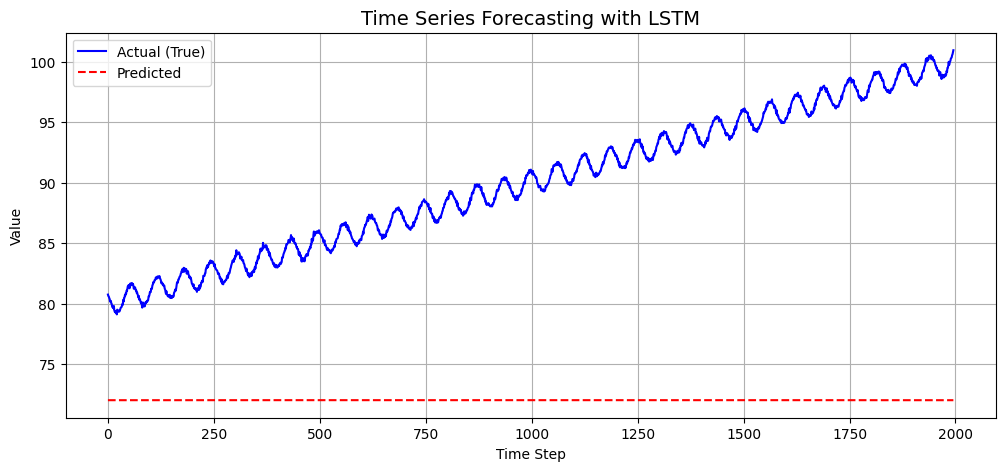


=== 🔍 시계열 분석 모델 소스 코드 핵심 분석 ===

1. 데이터 윈도우 생성 (Windowing):
   - 'sequence_length = 20' 설정을 통해 t-20 시점부터 t-1 시점까지의 데이터(X)로 t 시점의 데이터(y)를 예측하도록 데이터를 슬라이딩 윈도우 형태로 분할했습니다.

2. 3차원 입력 형태 정렬:
   - 텐서플로우 Keras의 순환신경망(RNN/LSTM) 레이어는 입력값으로 3차원 텐서인 '[batch_size, timesteps, features]' 구조를 요구합니다.
   - 따라서 'np.expand_dims'를 통해 피처(feature) 차원을 1로 확장해 줍니다.

3. LSTM 레이어 설계:
   - 'layers.LSTM(32, ...)'은 32개의 메모리 셀을 가진 LSTM 계층입니다. 시간에 흐름에 따른 가중치 소실 문제를 해결하고 장기적인 패턴(추세와 주기)을 효율적으로 잡아냅니다.
   - 마지막 시점의 요약된 상태 벡터만 다음 밀집층(Dense)으로 전달하기 위해 'return_sequences=False'로 설정했습니다.

4. 손실 함수 (MSE):
   - 시계열 예측은 특정 값을 수치로 맞추는 회귀(Regression) 연산이므로 오차의 제곱합인 'Mean Squared Error(MSE)'를 손실 함수로 적용해 가중치를 수렴시킵니다.



In [11]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# 1. 시계열 데이터 생성 (추세 + 사인파 + 노이즈)
def generate_time_series(signal_length, sequence_length):
    time = np.arange(0, signal_length, 0.1)
    # 추세(Trend)와 계절성(Seasonality)이 있는 데이터 생성
    series = 0.1 * time + np.sin(time) + np.random.normal(0, 0.1, size=len(time))

    # Window 단위로 데이터 분할 (X: 이전 sequence_length개의 데이터, y: 다음 1개의 데이터)
    X, y = [], []
    for i in range(len(series) - sequence_length):
        X.append(series[i:i + sequence_length])
        y.append(series[i + sequence_length])

    return np.array(X), np.array(y), series

# 변수 설정
sequence_length = 20  # 한 번에 학습할 타임스텝 크기 (과거 20개 데이터를 보고 미래 1개 예측)
raw_length = 1000

X, y, raw_series = generate_time_series(raw_length, sequence_length)

# LSTM 입력을 위해 3차원 변환 [samples, timesteps, features]
X = np.expand_dims(X, axis=-1)

# 학습 데이터와 테스트 데이터 분할
split_index = int(len(X) * 0.8)
X_train, X_test = X[:split_index], X[split_index:]
y_train, y_test = y[:split_index], y[split_index:]

print(f"Train Shape: {X_train.shape}, Test Shape: {X_test.shape}")

# 2. LSTM 기반 시계열 예측 모델 구축
model = models.Sequential([
    # LSTM 레이어: 시계열 데이터의 순차적 정보 및 장기 의존성 학습
    layers.LSTM(32, input_shape=(sequence_length, 1), activation='tanh', return_sequences=False),
    layers.Dense(16, activation='relu'),
    layers.Dense(1)  # 다음 1개 시점의 연속적인 수치 예측 (회귀)
])

# 3. 모델 컴파일 및 학습
model.compile(optimizer='adam', loss='mse', metrics=['mae'])
model.summary()

history = model.fit(
    X_train, y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

# 4. 테스트 데이터 예측 및 시각화
predictions = model.predict(X_test)

plt.figure(figsize=(12, 5))
plt.plot(range(len(y_test)), y_test, label='Actual (True)', color='b')
plt.plot(range(len(predictions)), predictions, label='Predicted', color='r', linestyle='--')
plt.title('Time Series Forecasting with LSTM', fontsize=14)
plt.xlabel('Time Step')
plt.ylabel('Value')
plt.legend()
plt.grid(True)
plt.show()

# 5. 소스 분석 설명
print("""
=== 🔍 시계열 분석 모델 소스 코드 핵심 분석 ===

1. 데이터 윈도우 생성 (Windowing):
   - 'sequence_length = 20' 설정을 통해 t-20 시점부터 t-1 시점까지의 데이터(X)로 t 시점의 데이터(y)를 예측하도록 데이터를 슬라이딩 윈도우 형태로 분할했습니다.

2. 3차원 입력 형태 정렬:
   - 텐서플로우 Keras의 순환신경망(RNN/LSTM) 레이어는 입력값으로 3차원 텐서인 '[batch_size, timesteps, features]' 구조를 요구합니다.
   - 따라서 'np.expand_dims'를 통해 피처(feature) 차원을 1로 확장해 줍니다.

3. LSTM 레이어 설계:
   - 'layers.LSTM(32, ...)'은 32개의 메모리 셀을 가진 LSTM 계층입니다. 시간에 흐름에 따른 가중치 소실 문제를 해결하고 장기적인 패턴(추세와 주기)을 효율적으로 잡아냅니다.
   - 마지막 시점의 요약된 상태 벡터만 다음 밀집층(Dense)으로 전달하기 위해 'return_sequences=False'로 설정했습니다.

4. 손실 함수 (MSE):
   - 시계열 예측은 특정 값을 수치로 맞추는 회귀(Regression) 연산이므로 오차의 제곱합인 'Mean Squared Error(MSE)'를 손실 함수로 적용해 가중치를 수렴시킵니다.
""")
